# Matplotlib Library (Part 2)

**OO Matplotlib, Advanced Plot Quality, Subplots, Bar/Pie Best Practices**

---


## Table of Contents
1. [Setup & Matplotlib Styles](#setup--matplotlib-styles)
2. [Object-Oriented Matplotlib: The Professional Approach](#object-oriented-matplotlib-the-professional-approach)
3. [Line Charts (Advanced): Legends, Scales, and Annotations](#line-charts-advanced-legends-scales-and-annotations)
4. [Scatter Charts (Advanced): Grouping, Color Mapping, and Subsets](#scatter-charts-advanced-grouping-color-mapping-and-subsets)
5. [Subplots (Advanced): Shared Axes, Layout, and Titles](#subplots-advanced-shared-axes-layout-and-titles)
6. [Bar Charts (Advanced): Error Bars and Grouped Bars](#bar-charts-advanced-error-bars-and-grouped-bars)
7. [Pie Charts (Advanced): Explode, Start Angle, and Alternatives](#pie-charts-advanced-explode-start-angle-and-alternatives)
8. [Working with Real Data (Pandas)](#working-with-real-data-pandas)
9. [Exercises](#professional-figure-construction)


---


### By the end of this week, students will be able to:

- Use the **object‑oriented (OO)** Matplotlib approach (`fig, ax = plt.subplots()`).
- Build well-structured figures with multiple axes and advanced layout control.
- Create and customize **line**, **scatter**, **bar**, and **pie** charts at a higher professional level.
- Add **annotations**, control **ticks**, **scales**, and **styles** for readability.
- Read data using **Pandas** and generate report-ready visualizations.
- Complete a practical **tasks** (Data Analysis & Visualization).




## Setup & Matplotlib Styles


In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


### Optional: use a built-in style

Matplotlib has ready-made styles that change how plots look (colors, grids, fonts, etc.).
Styles help make plots cleaner and nicer without writing extra code.

See Available Styles

To see the styles that Matplotlib provides, use:


In [ ]:
plt.style.available[:10]  # uncomment to preview


['Solarize_Light2',
 '_classic_test_patch',
 '_mpl-gallery',
 '_mpl-gallery-nogrid',
 'bmh',
 'classic',
 'dark_background',
 'fast',
 'fivethirtyeight',
 'ggplot']

In [ ]:
# Example: apply a style (optional)
plt.style.use("ggplot")


After this, all plots you draw will use this style unless you change it again.

Notes

- Using a style is optional.

- Styles only affect how the plot looks, not the data or results.

- Styles are useful when creating plots for reports or presentations.

- If you do not choose a style, Matplotlib uses the default style.

## Object-Oriented Matplotlib: The Professional Approach


### Why OO approach?

While `plt.plot(...)` is convenient, the OO approach is clearer for:
- multiple subplots
- complex layouts
- advanced customization

The OO pattern:
1. Create figure + axes: `fig, ax = plt.subplots()`
2. Plot using the axes: `ax.plot(...)`
3. Customize axes: `ax.set_title(...)`, `ax.grid(...)`, etc.


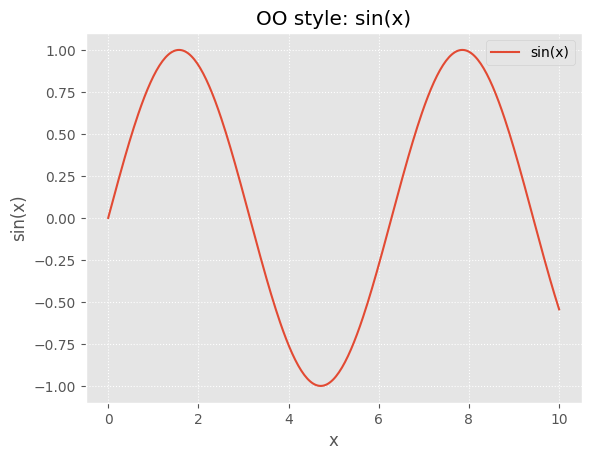

In [ ]:
x = np.linspace(0, 10, 300)
y = np.sin(x)

fig, ax = plt.subplots()
ax.plot(x, y, label="sin(x)")
ax.set_title("OO style: sin(x)")
ax.set_xlabel("x")
ax.set_ylabel("sin(x)")
ax.grid(True, linestyle=":")
ax.legend()
plt.show()


### Multiple axes in one figure

`plt.subplots(r, c)` returns:
- a single `ax` if r*c = 1
- an array of axes otherwise


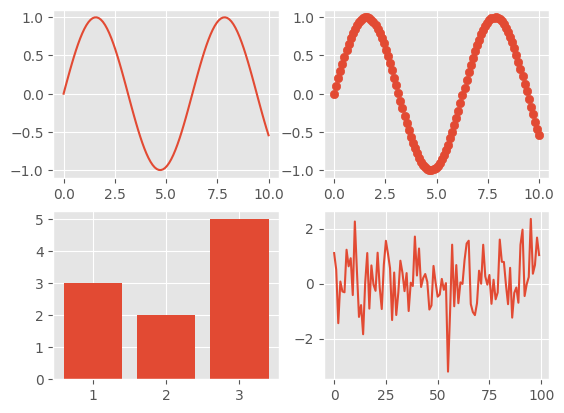

In [ ]:
fig, ax = plt.subplots(2, 2)

ax[0, 0].plot(x, y)

ax[0, 1].scatter(x, y)

ax[1, 0].bar([1,2,3], [3,2,5])

rng = np.random.default_rng()
ax[1, 1].plot(rng.normal(size=100))

plt.show()

## Line Charts (Advanced): Legends, Scales, and Annotations


### 1) Adding reference lines and annotations

Annotations help explain *why* a feature matters (peak, threshold, event).


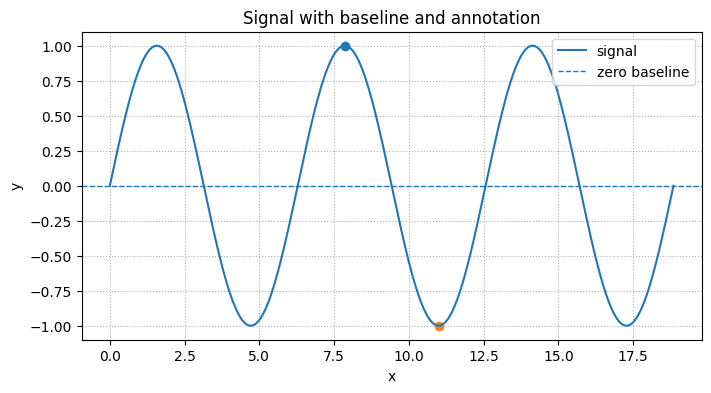

In [3]:
x = np.linspace(0, 6*np.pi, 800)
y = np.sin(x)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, y, label="signal")
ax.axhline(0, linestyle="--", linewidth=1, label="zero baseline")

# annotate a peak (approx)
idx = np.argmax(y)
ax.scatter([x[idx]], [y[idx]])

idmin = np.argmin(y)
ax.scatter([x[idmin]], [y[idmin]])


ax.set_title("Signal with baseline and annotation")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid(True, linestyle=":")
ax.legend()
plt.show()


## Scatter Charts (Advanced): Grouping, Color Mapping, and Subsets


### Scatter plots with groups

A common real-world scenario is comparing categories/classes.
We can plot subsets with different markers and a legend.


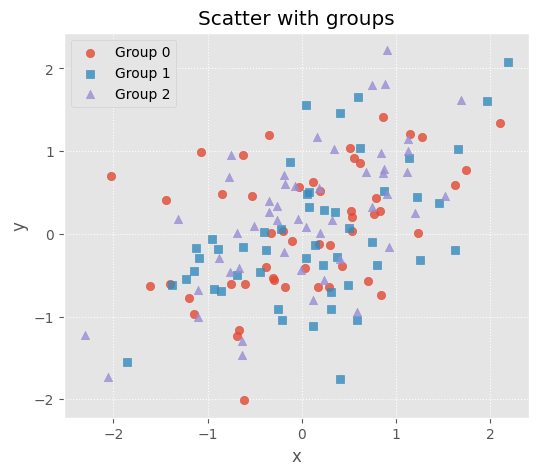

In [ ]:
rng = np.random.RandomState(1)
n = 150
x = rng.normal(size=n)
y = 0.5*x + rng.normal(scale=0.7, size=n)
group = rng.randint(0, 3, size=n)

fig, ax = plt.subplots(figsize=(6, 5))
markers = ["o", "s", "^"]
labels = ["Group 0", "Group 1", "Group 2"]

for g in range(3):
    mask = (group == g)
    ax.scatter(x[mask], y[mask], marker=markers[g], alpha=0.8, label=labels[g])

ax.set_title("Scatter with groups")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid(True, linestyle=":")
ax.legend()
plt.show()


## Subplots (Advanced): Shared Axes, Layout, and Titles


### Shared axes for clean comparisons

When comparing multiple plots, sharing x/y scales improves readability.


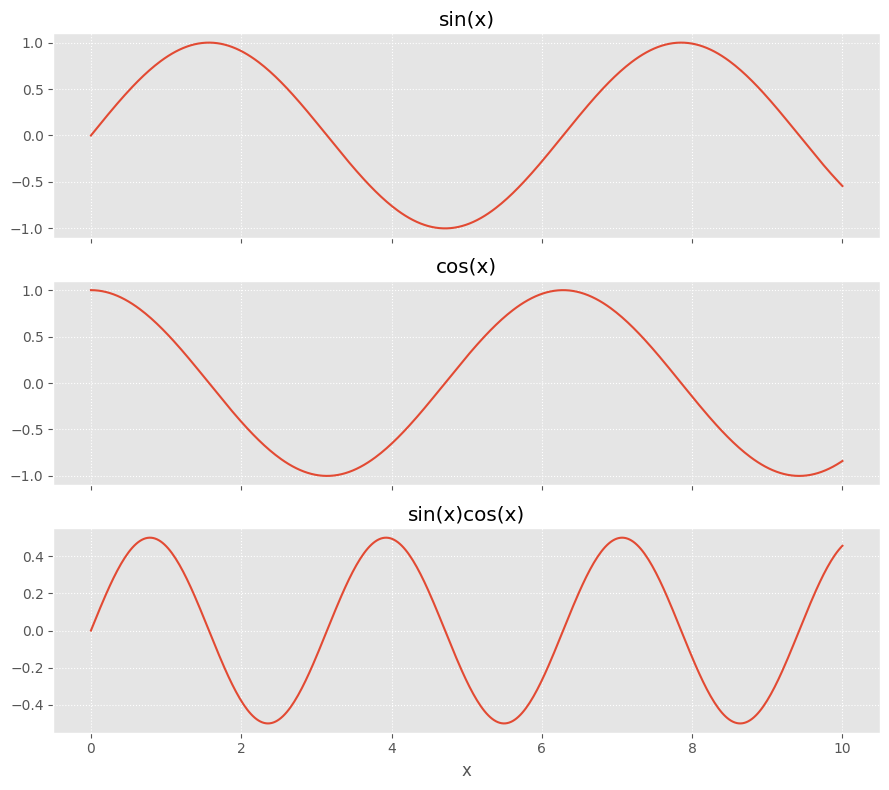

In [ ]:
x = np.linspace(0, 10, 400)
signals = [np.sin(x), np.cos(x), np.sin(x)*np.cos(x)]

# subplots(row = 3, column = 1 , ...... , sharex=True(all plor share same x axis) )
fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
titles = ["sin(x)", "cos(x)", "sin(x)cos(x)"]

'''
What zip produces
It creates pairs like this:
(axes[0], signals[0], titles[0])
(axes[1], signals[1], titles[1])
(axes[2], signals[2], titles[2])
'''
for ax, s, t in zip(axes, signals, titles):
    ax.plot(x, s)
    ax.set_title(t)
    ax.grid(True, linestyle=":")

# axes[-1] = last subplot (bottom one)
axes[-1].set_xlabel("x")
plt.tight_layout()
plt.show()


## Bar Charts (Advanced): Grouped Bars


### Grouped bars (two metrics per category)

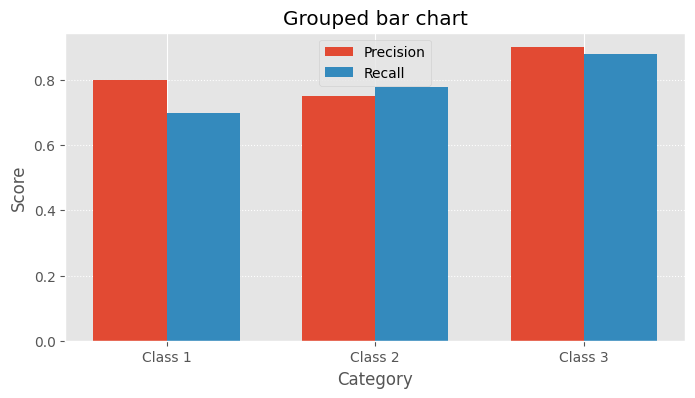

In [ ]:
categories = ["Class 1", "Class 2", "Class 3"]
precision = np.array([0.80, 0.75, 0.90])
recall = np.array([0.70, 0.78, 0.88])

# Class 1 → 0 , Class 2 → 1 , Class 3 → 2
x = np.arange(len(categories))

# Controls spacing between bars
width = 0.35

fig, ax = plt.subplots(figsize=(8, 4))

# x - width/2 -> Precision bar (left)  , ...... ,  width → bar thickness , ......
ax.bar(x - width/2, precision, width, label="Precision")
# x + width/2 -> Recall bar (right) , ...... ,  width → bar thickness , ......
ax.bar(x + width/2, recall, width, label="Recall")

ax.set_title("Grouped bar chart")
ax.set_xlabel("Category")
ax.set_ylabel("Score")

# Put ticks at positions 0,1,2
ax.set_xticks(x)
# Replace numbers with class names
ax.set_xticklabels(categories)

ax.grid(True, axis="y", linestyle=":")
ax.legend()
plt.show()


## Pie Charts (Advanced): Explode, Start Angle, and Alternatives


Pie charts are still possible, but keep them simple.

We also discuss when a **bar chart** is a better choice.


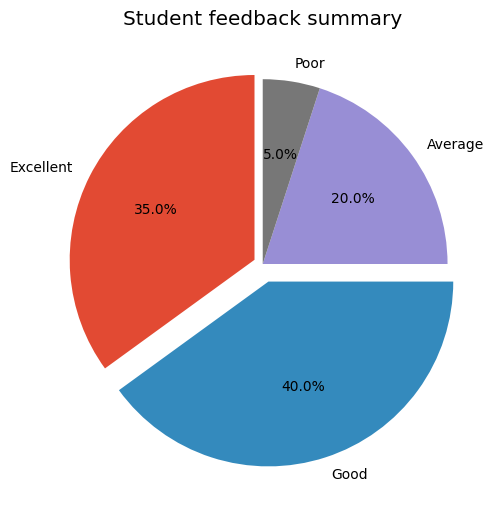

In [ ]:
labels = ["Excellent", "Good", "Average", "Poor"]
sizes = [35, 40, 20, 5]
explode = [0.05, 0.1, 0, 0]  # highlight first slice

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(sizes, labels=labels, autopct="%1.1f%%", startangle=90, explode=explode)
ax.set_title("Student feedback summary")
plt.show()


## Working with Real Data (Pandas)


In professional work, data often comes from CSV/Excel databases.

We'll create a small DataFrame and visualize it.


In [ ]:
df = pd.DataFrame({
    "week": np.arange(1, 11),
    "attendance": [28, 30, 29, 27, 31, 32, 30, 29, 33, 34],
    "avg_score": [71, 74, 73, 70, 76, 78, 77, 75, 80, 82]
})
df


,week,attendance,avg_score
0,1,28,71
1,2,30,74
2,3,29,73
3,4,27,70
4,5,31,76
5,6,32,78
6,7,30,77
7,8,29,75
8,9,33,80
9,10,34,82


### Line plot from DataFrame

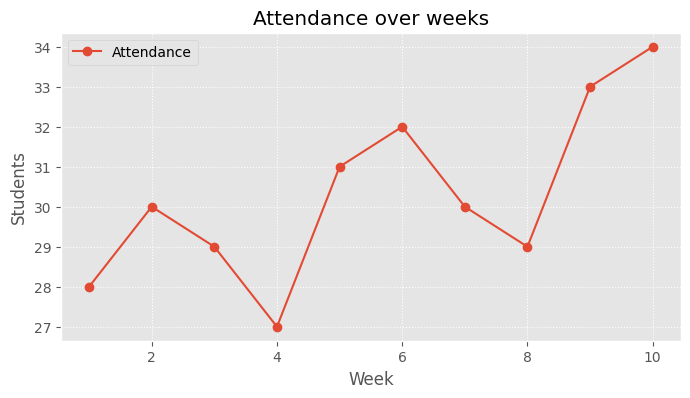

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(df["week"], df["attendance"], marker="o", label="Attendance")
ax.set_title("Attendance over weeks")
ax.set_xlabel("Week")
ax.set_ylabel("Students")
ax.grid(True, linestyle=":")
ax.legend()
plt.show()


### Two y-axes (advanced; use carefully)

Useful when variables have different units/scales.


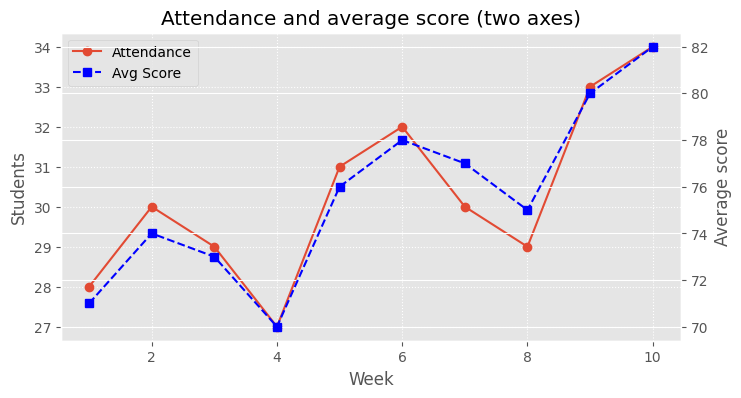

In [ ]:
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(df["week"], df["attendance"], marker="o", label="Attendance")
ax1.set_xlabel("Week")
ax1.set_ylabel("Students")
ax1.grid(True, linestyle=":")

# Creates a second y-axis sharing the same x-axis
ax2 = ax1.twinx()


ax2.plot(df["week"], df["avg_score"], c = 'b', marker="s", linestyle="--", label="Avg Score")
ax2.set_ylabel("Average score")

# build a combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

plt.title("Attendance and average score (two axes)")
plt.show()
